In [3]:

import numpy as np
import matplotlib.pyplot as plt
from bisect import bisect_left
 
def lattice(n, a):
    """Siec fcc: n x n x n komorek elementarnych, 4 atomy na komorke, stala sieci a."""
    basis = np.array([[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]])
    g = np.arange(n)
    cells = np.array(np.meshgrid(g, g, g, indexing="ij")).reshape(3, -1).T
    return ((cells[:, None, :] + basis[None, :, :]) * a).reshape(-1, 3)
 
def pbc_delta(ri, rj, L):
    d = ri - rj
    return d - L * np.round(d / L)
 
def energy_forces(pos, L):
    d = pbc_delta(pos[:, None, :], pos[None, :, :], L)     # (N,N,3)
    r = np.linalg.norm(d, axis=2)
    np.fill_diagonal(r, np.inf)
    mask = r < RC
    x6 = np.where(mask, (R / r) ** 6, 0.0)
    x12 = x6 ** 2
    v_rc = EPS * ((R / RC) ** 12 - 2 * (R / RC) ** 6)
    E = 0.5 * np.sum(np.where(mask, EPS * (x12 - 2 * x6) - v_rc, 0.0))
    f_scal = np.where(mask, 12 * EPS / r * (x12 - x6), 0.0)  # F>0 odpychanie
    F = np.sum((f_scal / r)[:, :, None] * d, axis=1)
    # wirial: suma_{i<j} r_ij . F_ij = 0.5 * suma_{i!=j} f_scal * r
    W = 0.5 * np.sum(12 * EPS * (x12 - x6))
    return E, F, W
 
def verlet_step(r, p, F, tau):
    p = p + 0.5 * F * tau
    r = (r + p / MASS * tau) % L
    E, F, W = energy_forces(r, L)
    p = p + 0.5 * F * tau
    return r, p, F, E, W
 
# ---------- Nowe funkcje ----------
def maxwell_momenta(shape, T0):
    """Energia kinetyczna E = -1/2 kT ln(lambda), losowe znaki, brak ruchu srodka masy."""
    lam = 1.0 - rng.random(shape)                      # liczby z (0,1]
    v = np.sqrt(-KB * T0 * np.log(lam) / MASS)         # |v| z E = 1/2 m v^2
    p = MASS * v * rng.choice([-1, 1], size=shape)
    return p - p.mean(axis=0)
 
def temperature(p):
    return np.sum(p**2 / (2 * MASS)) * 2 / (3 * len(p) * KB)
 
def pressure(virial, T, V):
    return (len(p0) * KB * T + virial / 3) / V         # eV/A^3
 
def thermostat(p, T, mode):
    if mode == "scale":                                # proste przeskalowanie
        return p * np.sqrt(T0 / T)
    if mode == "berendsen":
        return p * np.sqrt(1 + tau / TAU_T * (T0 / T - 1))
    return p                                           # mode == "none"
 
# ---------- Parametry (Ar; A, eV, ps) ----------
EPS, R = 0.0104, 3.82
N_CELLS, A = 2, np.sqrt(2) * R   # fcc: odleglosc najblizszych sasiadow = R
L = N_CELLS * A
RC = min(2.5 * R, L / 2)
MASS = 39.948 / 9648.5
KB, T0 = 8.617e-5, 500
EV_A3_TO_BAR = 1.602e6
N_STEPS = 5000       # termalizacja + zbieranie statystyk
tau = 0.001
TAU_T = 0.01                        # stala sprzezenia Berendsena [ps]
rng = np.random.default_rng(1)
 
pos = lattice(N_CELLS, A)
r0 = (pos + 0.1 * (2 * rng.random(pos.shape) - 1)) % L
p0 = maxwell_momenta(r0.shape, T0)
 
r, p = r0.copy(), p0.copy()
_, F, _ = energy_forces(r, L)
T_t, P_t = np.zeros(N_STEPS), np.zeros(N_STEPS)
traj = np.zeros((N_STEPS+1, r0.shape[0], 3))
for s in range(N_STEPS):
    r, p, F, E, W = verlet_step(r, p, F, tau)
    T = temperature(p)
    T_t[s], P_t[s] = T, pressure(W, T, L**3) * EV_A3_TO_BAR
    p = thermostat(p, T, 'scale')
 
    traj[s] = r

np.save("zapis_trajektori.npy",traj)

(5000, 32, 3)
(992,)


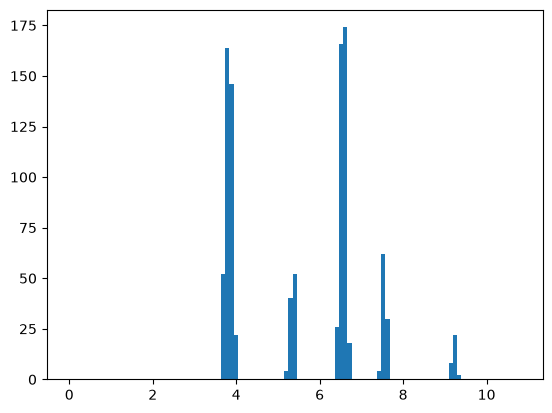

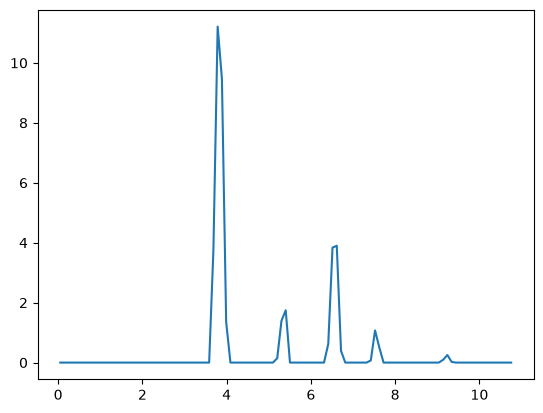

(992,)


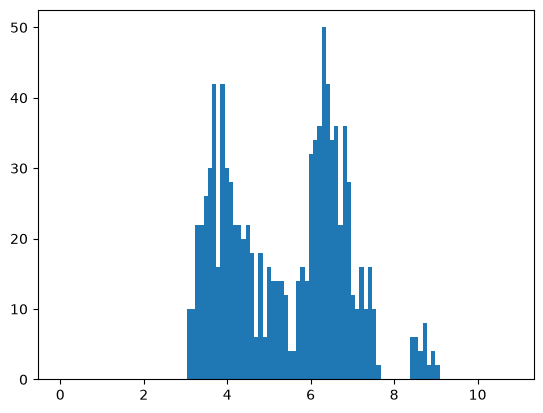

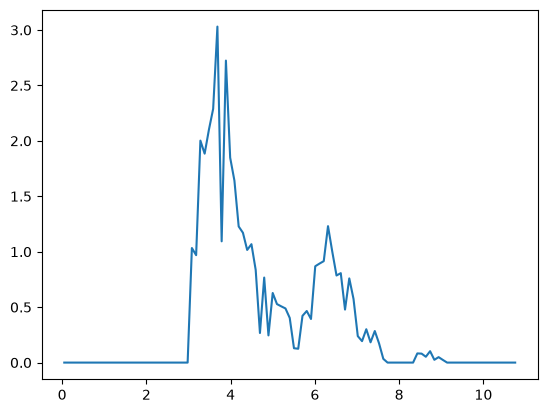

(992,)


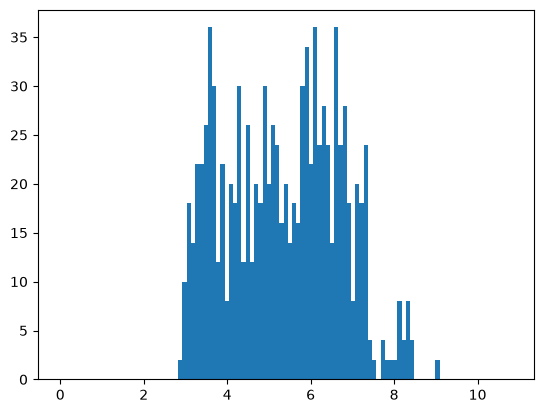

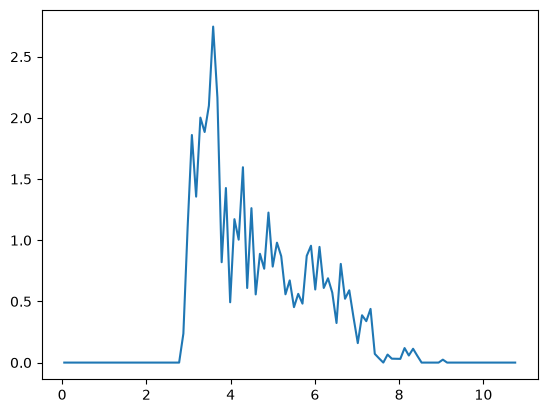

(992,)


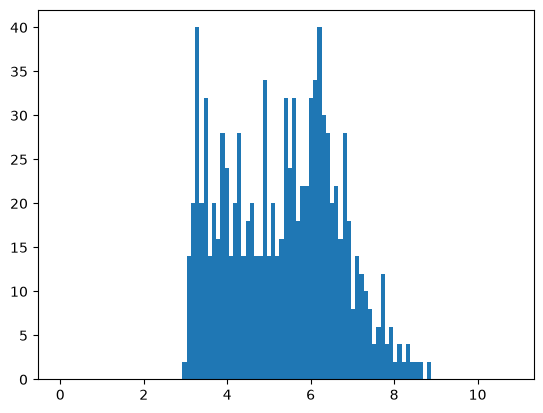

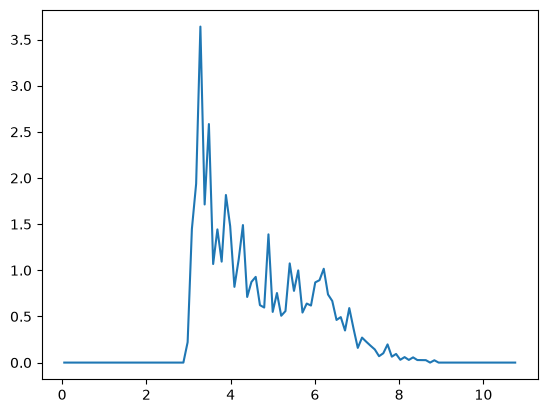

(992,)


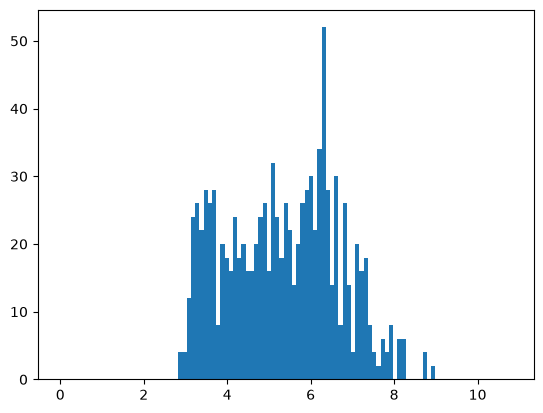

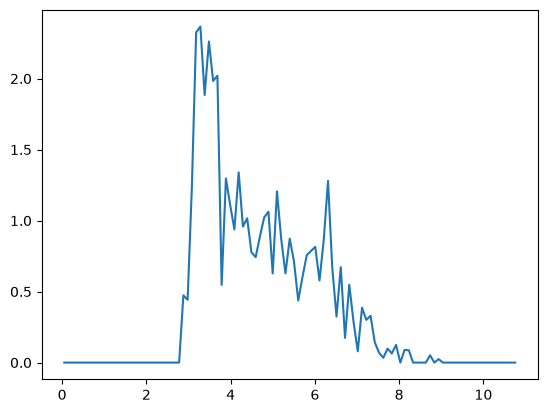

(992,)


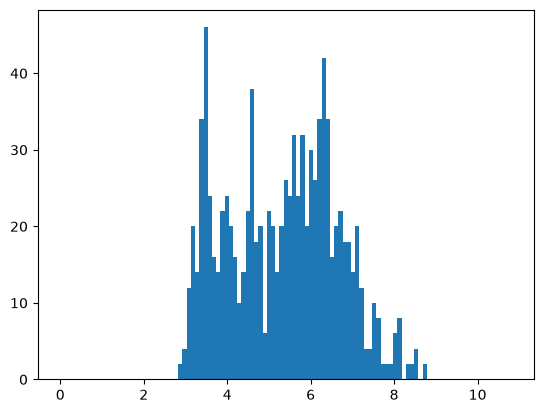

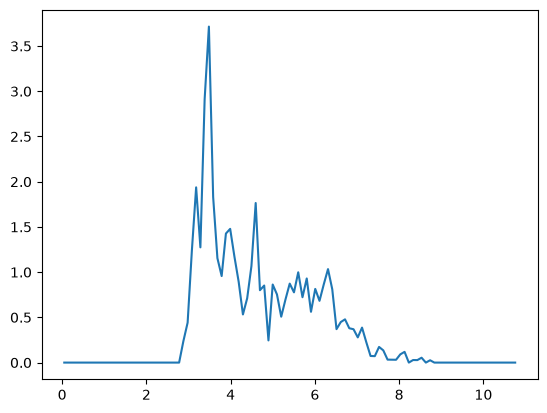

(992,)


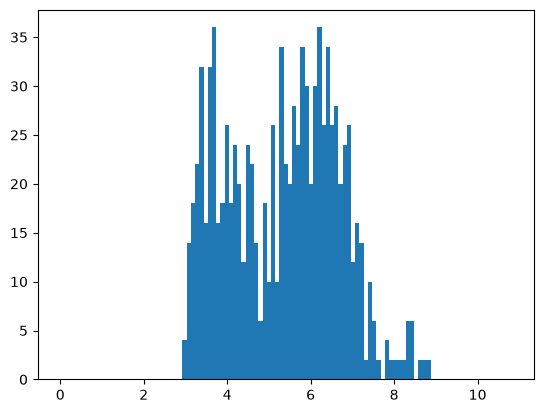

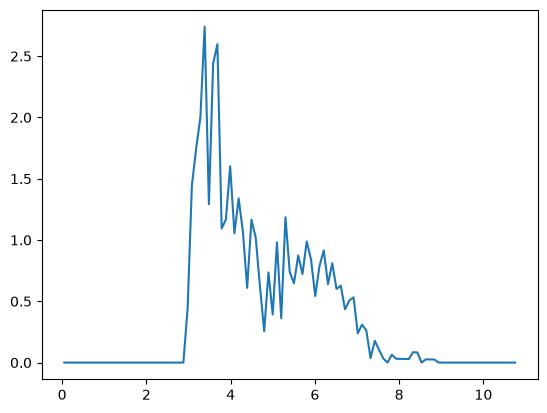

(992,)


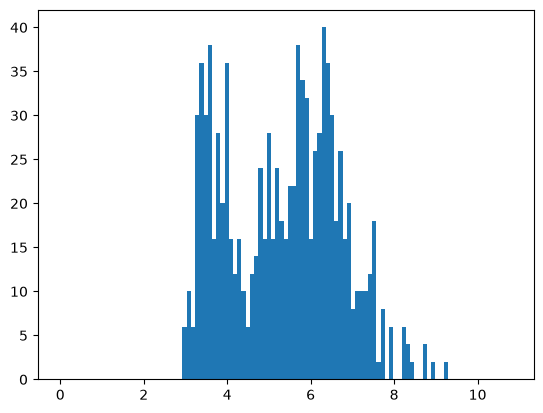

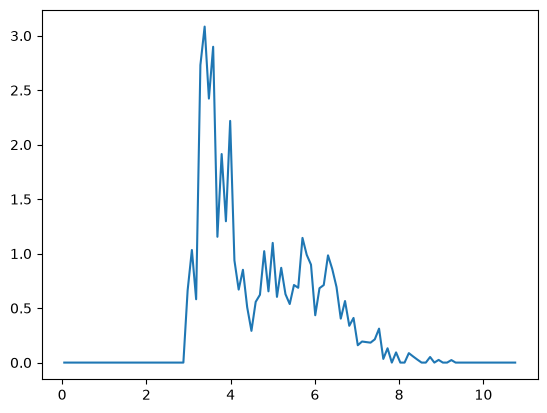

(992,)


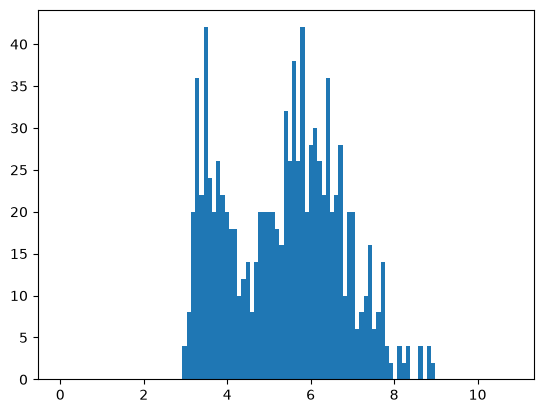

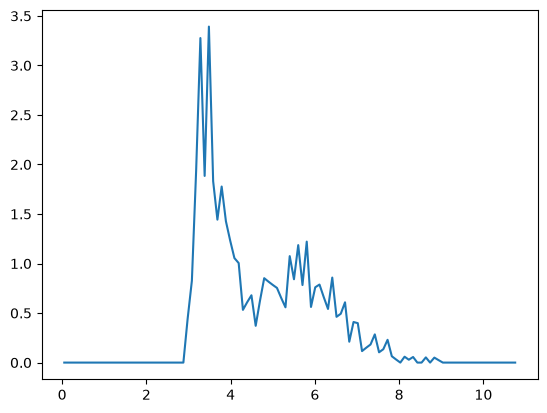

(992,)


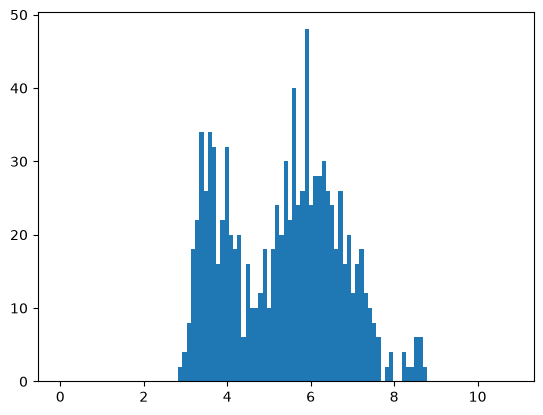

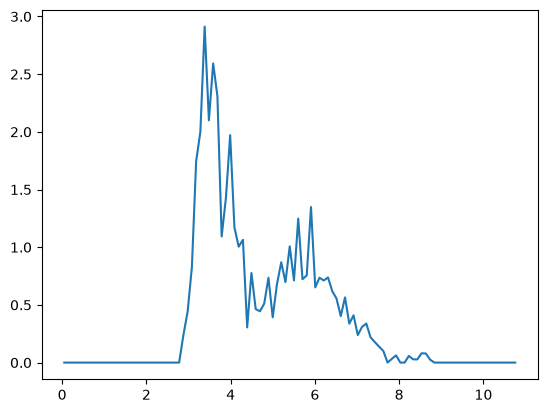

(992,)


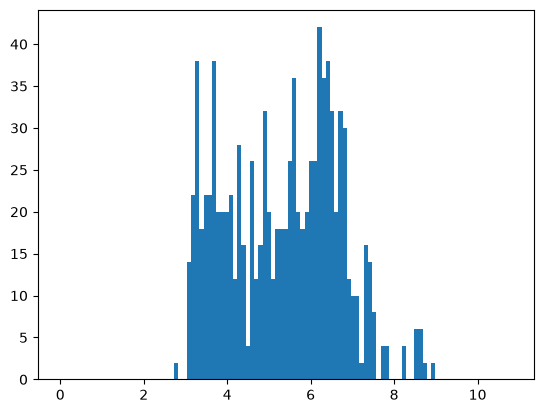

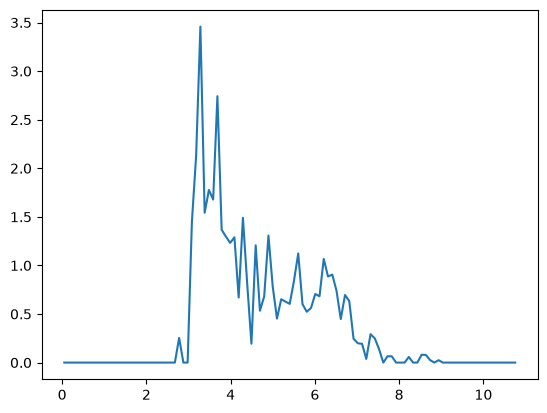

(992,)


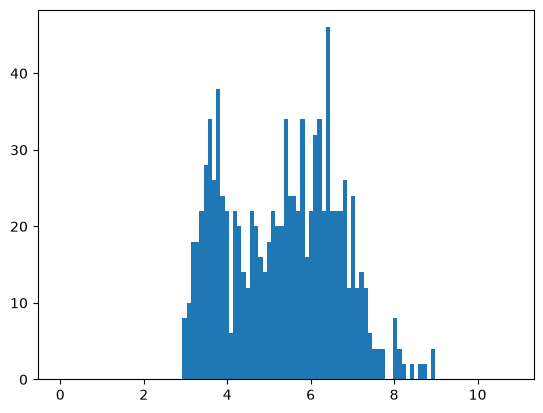

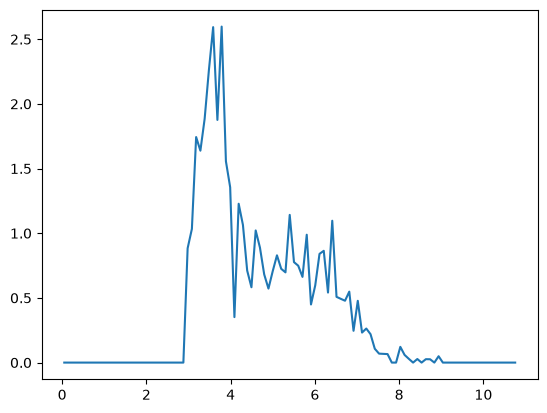

(992,)


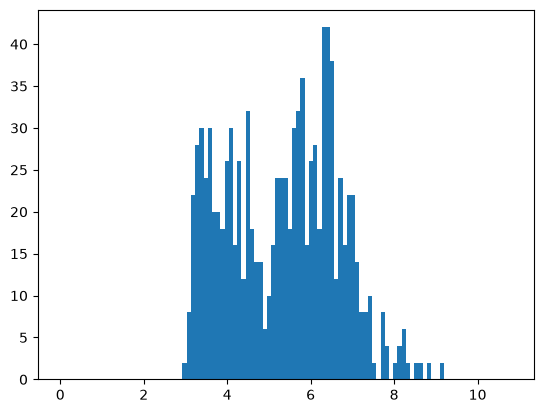

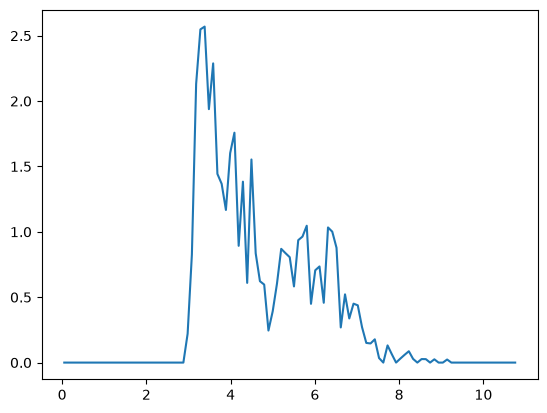

(992,)


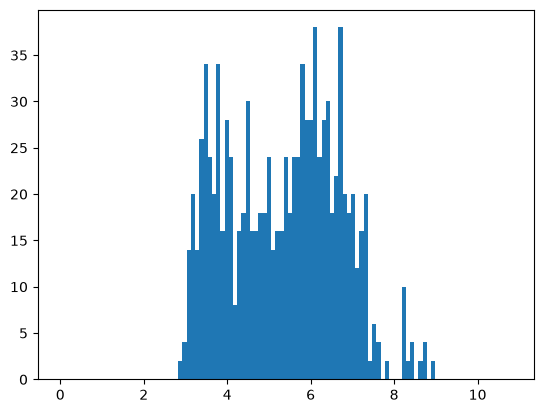

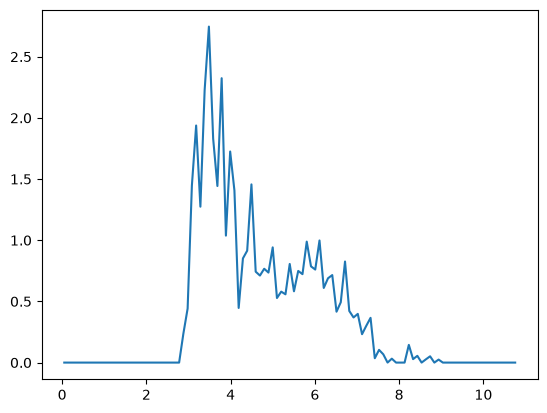

(992,)


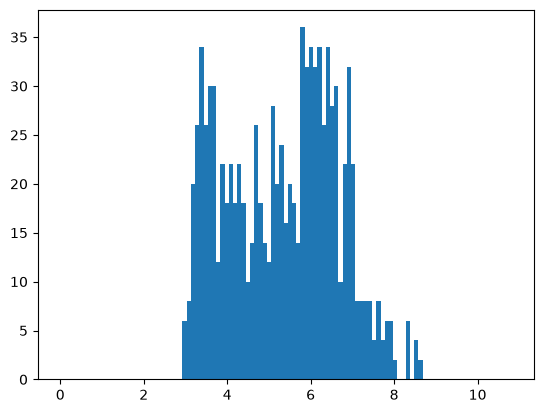

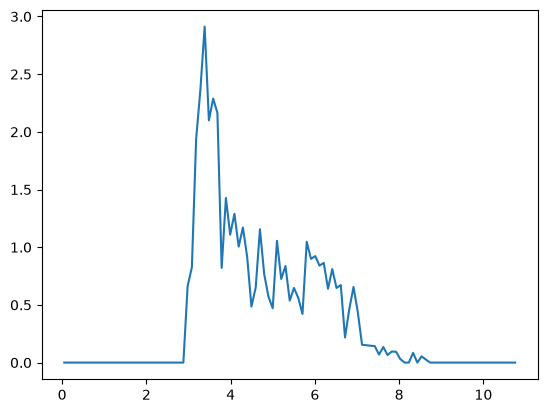

(992,)


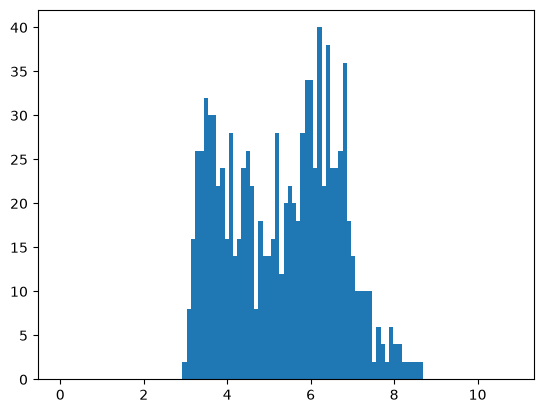

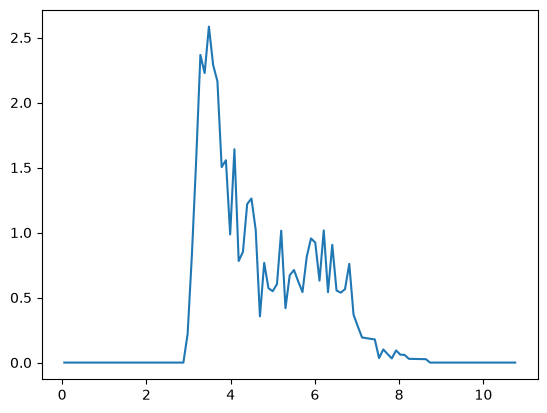

(992,)


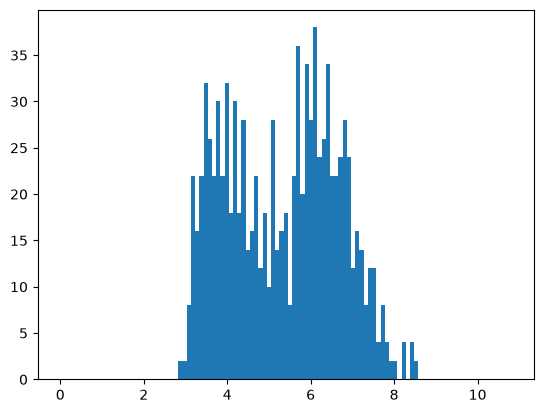

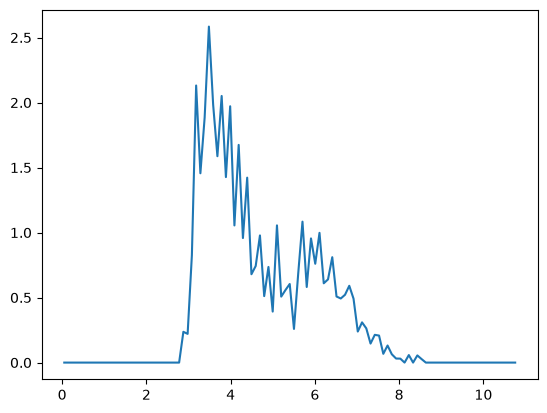

(992,)


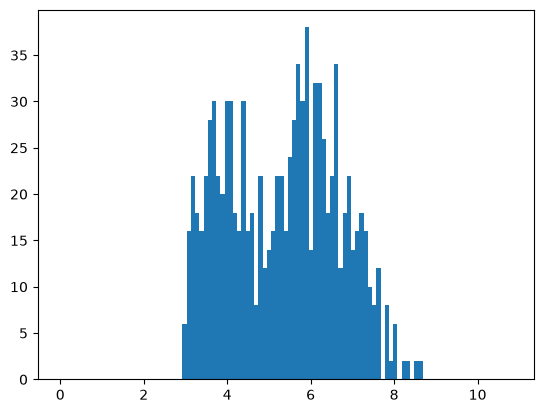

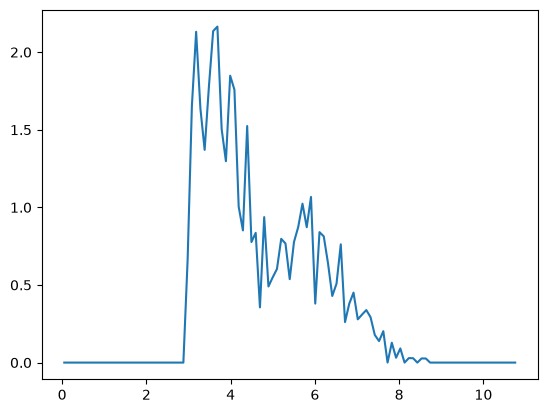

(992,)


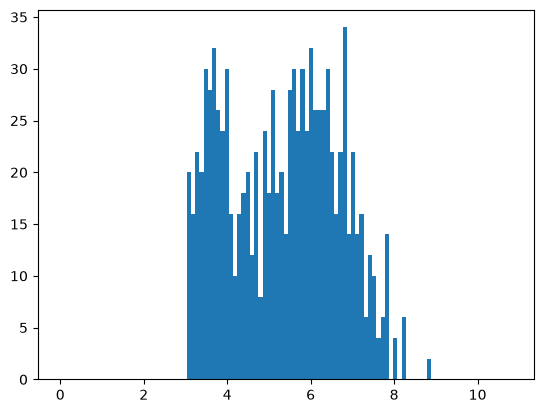

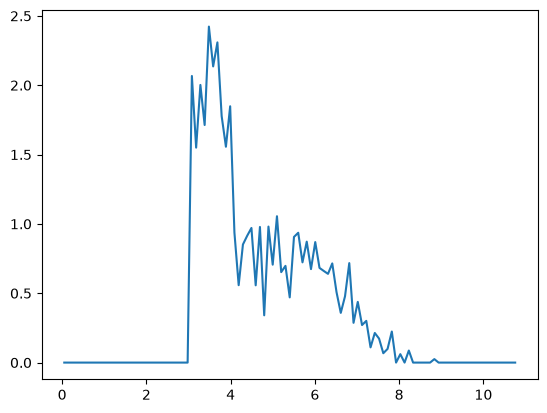

(992,)


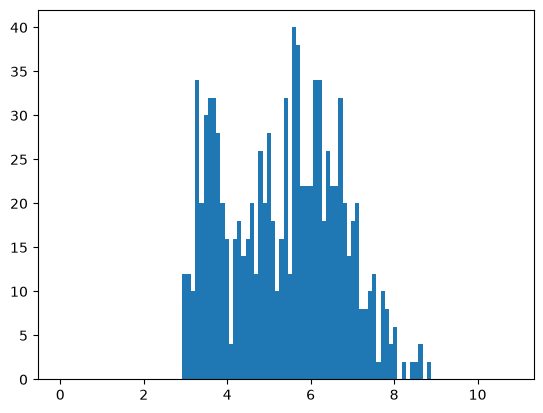

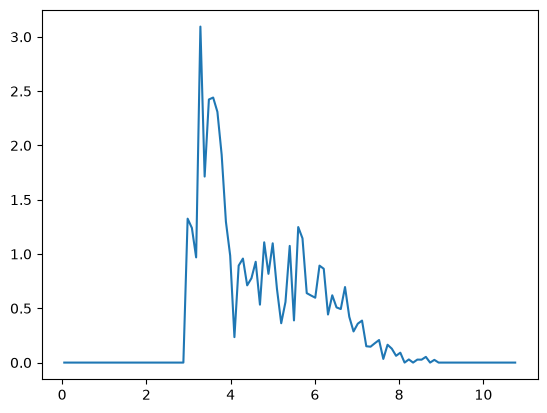

(992,)


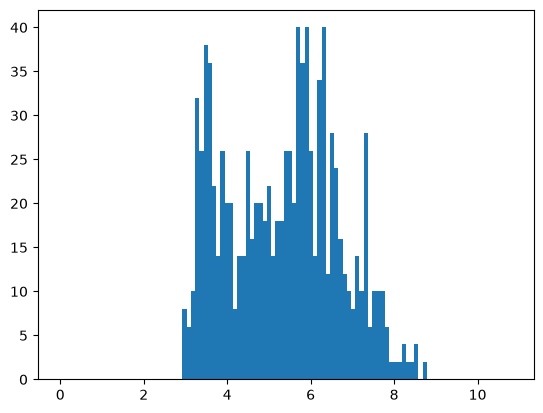

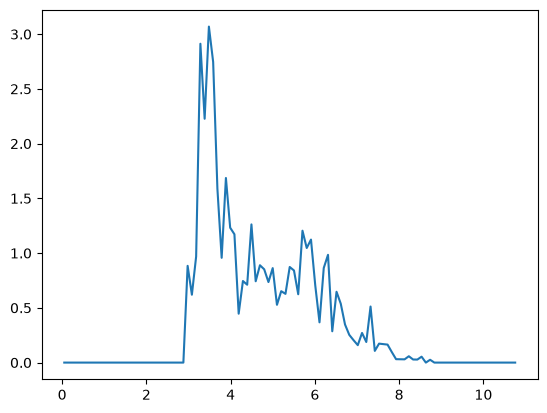

(992,)


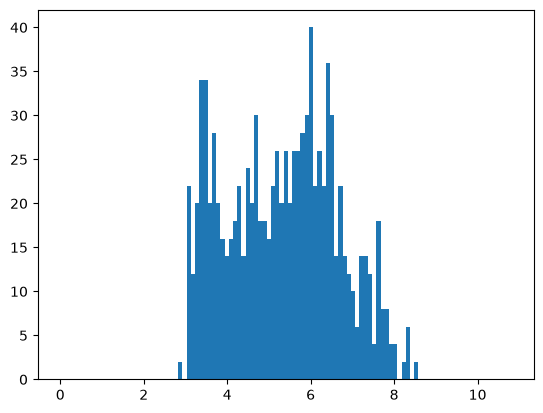

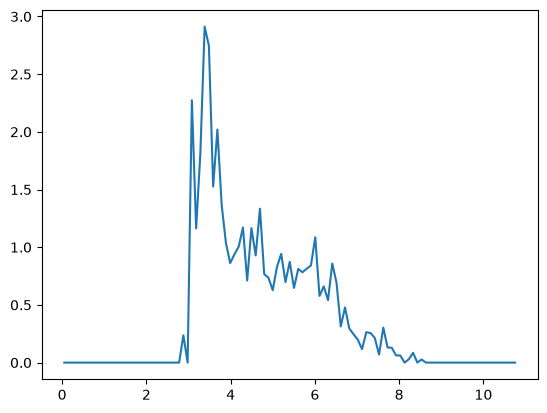

(992,)


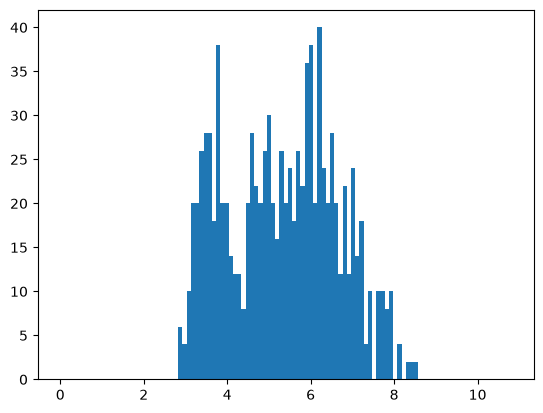

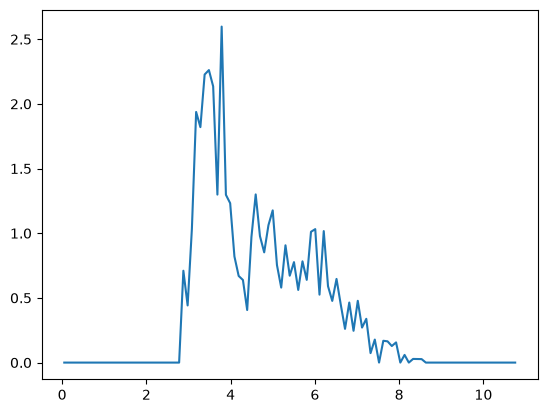

(992,)


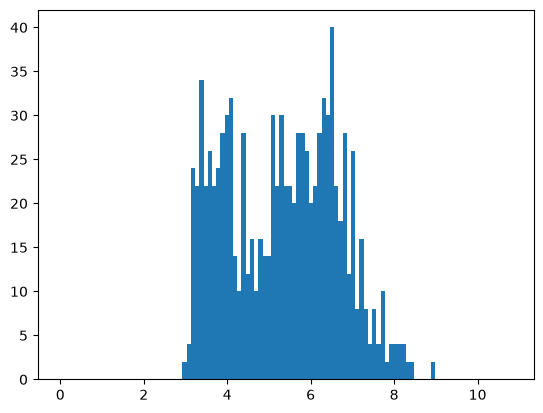

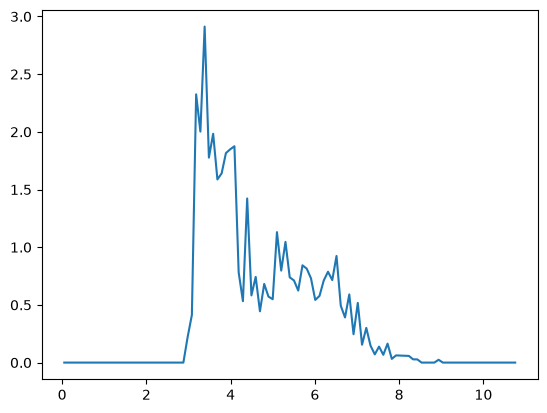

(992,)


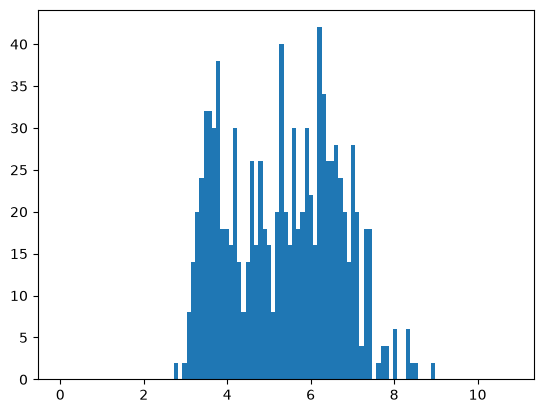

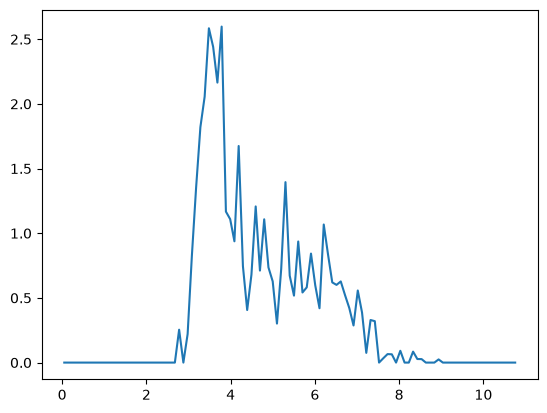

(992,)


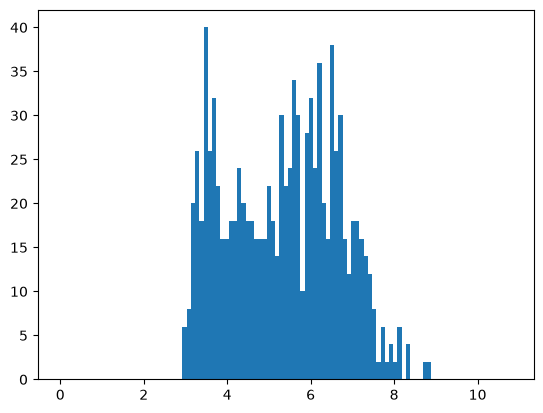

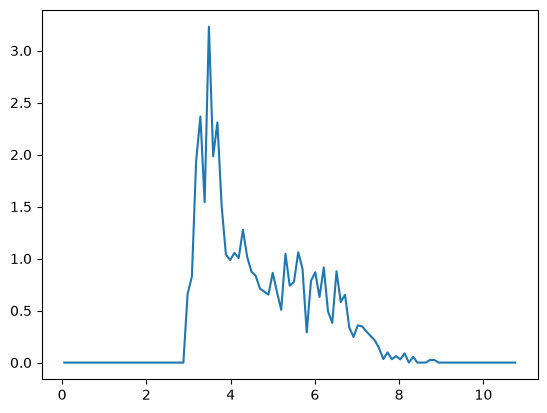

(992,)


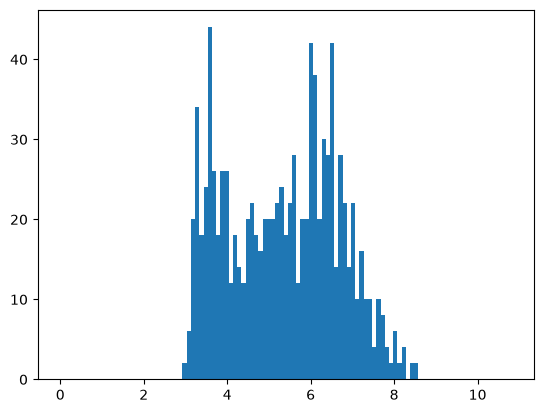

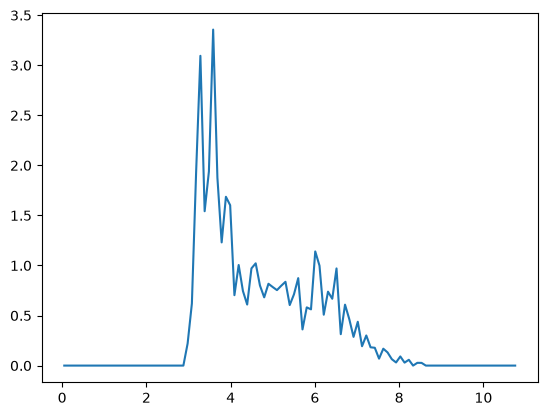

(992,)


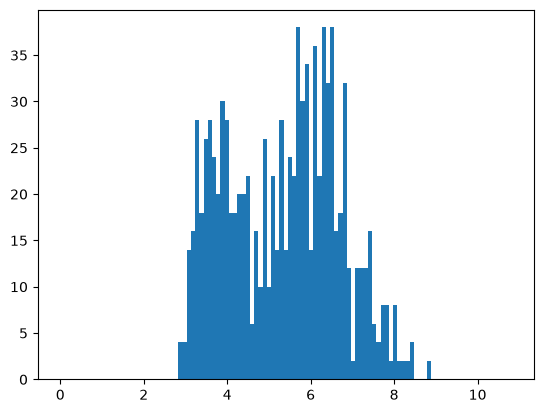

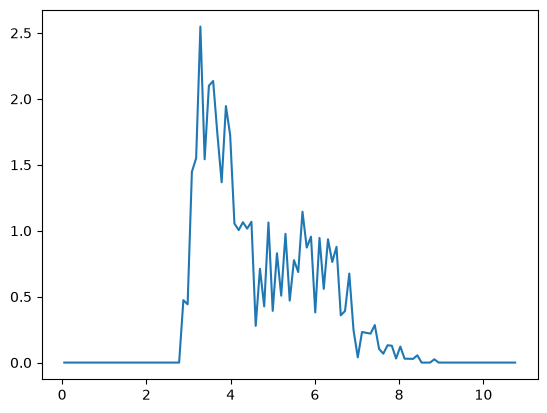

(992,)


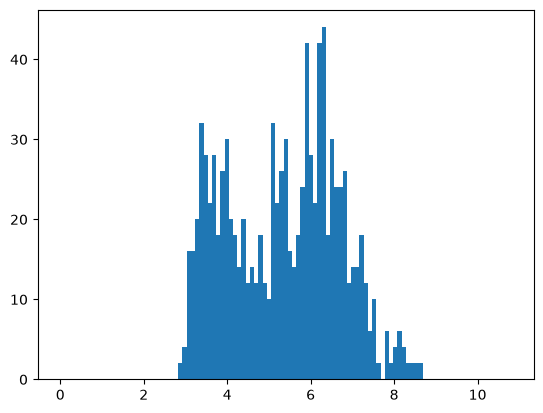

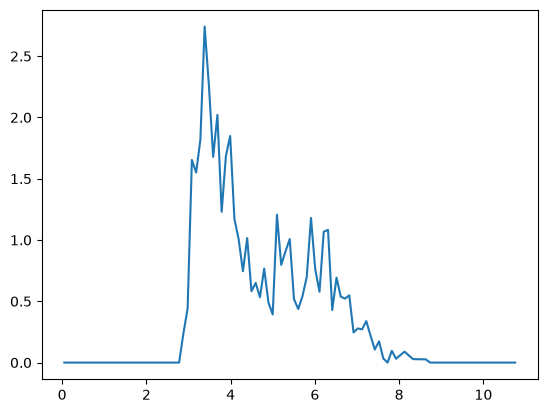

(992,)


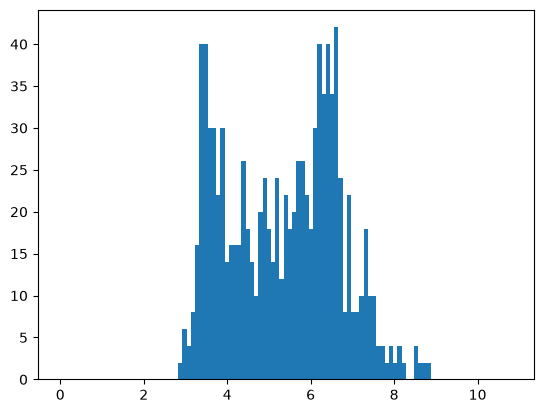

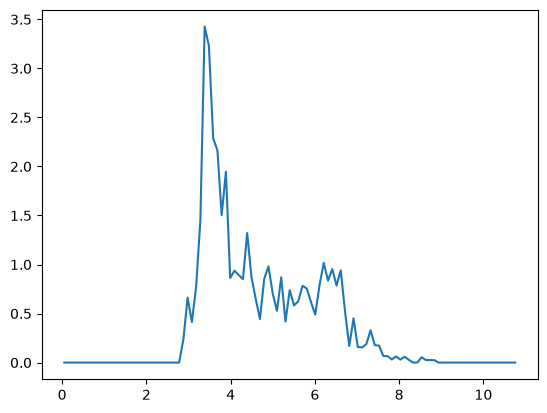

(992,)


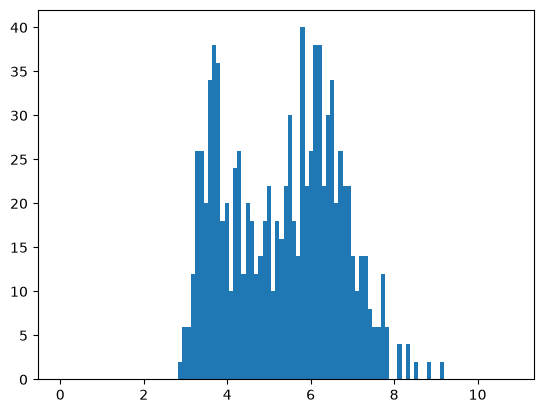

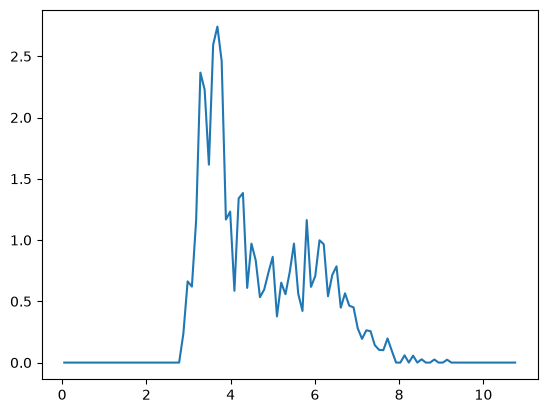

(992,)


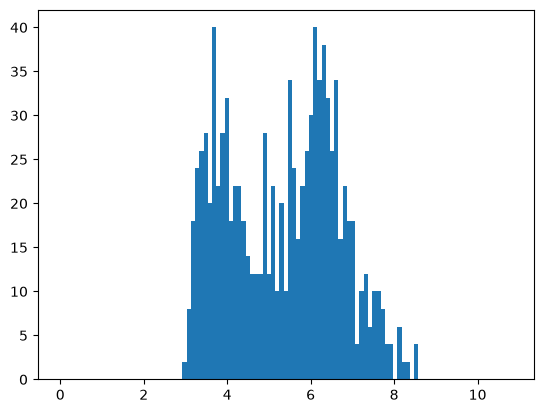

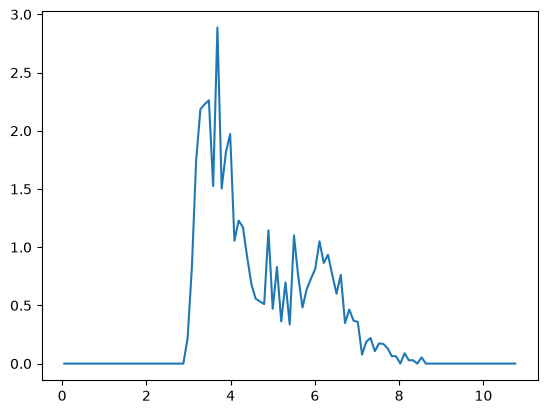

(992,)


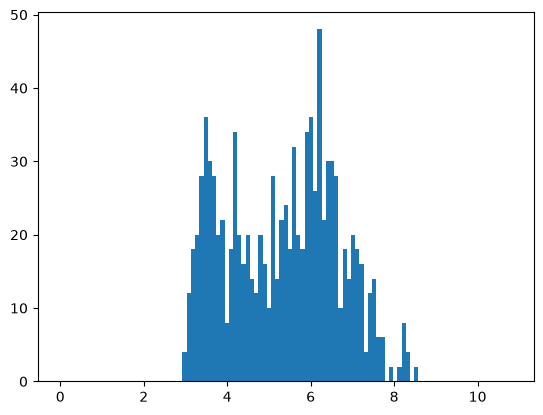

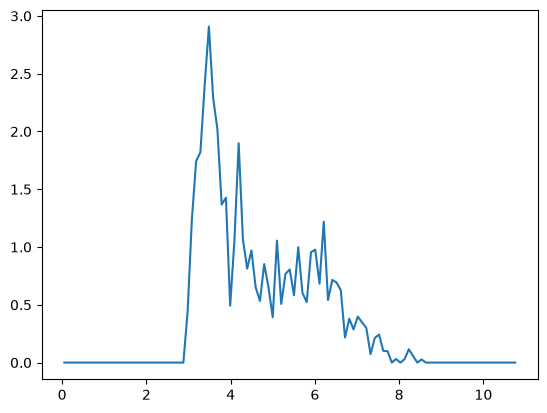

(992,)


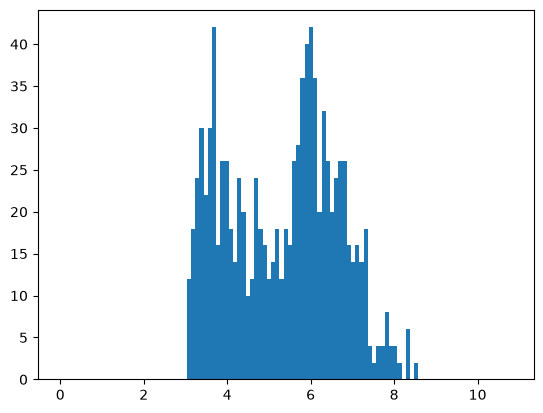

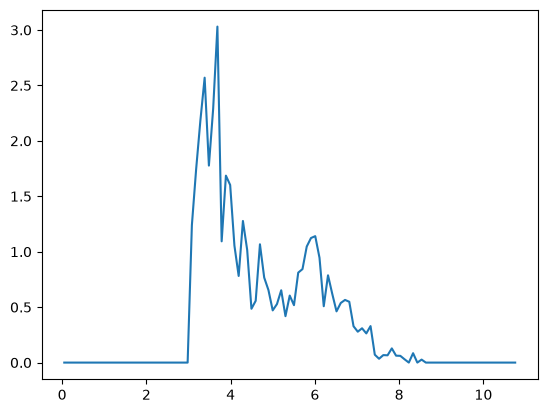

(992,)


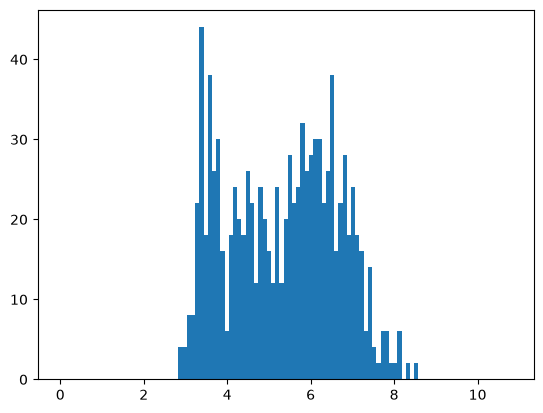

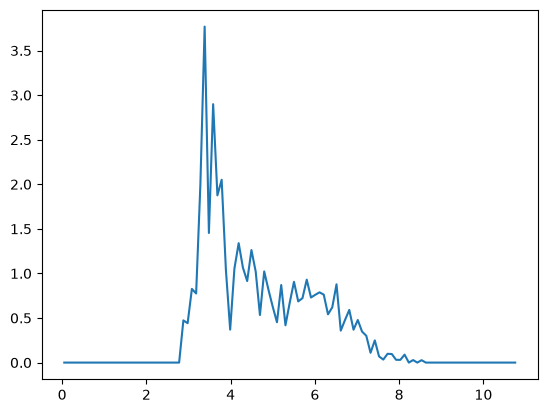

(992,)


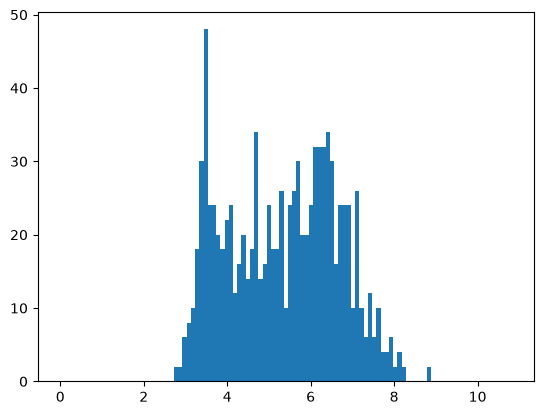

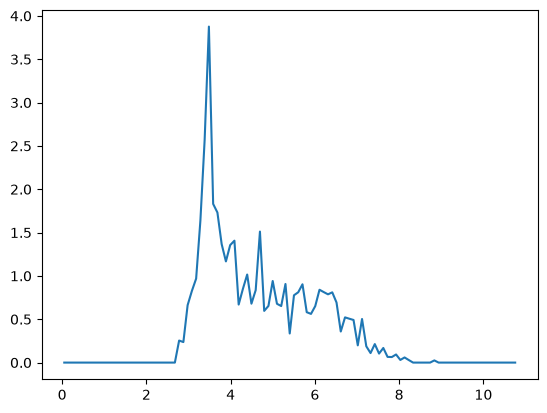

(992,)


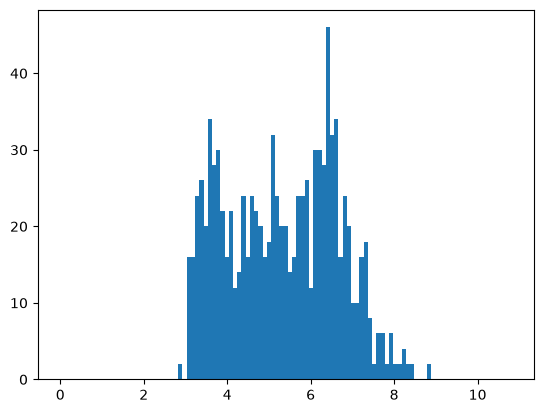

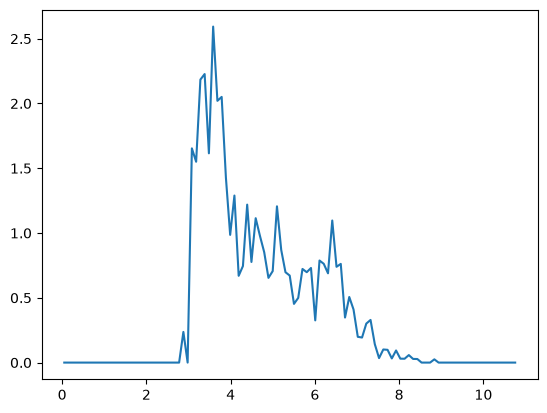

(992,)


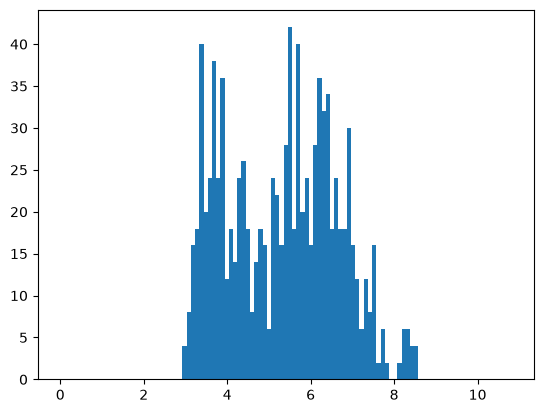

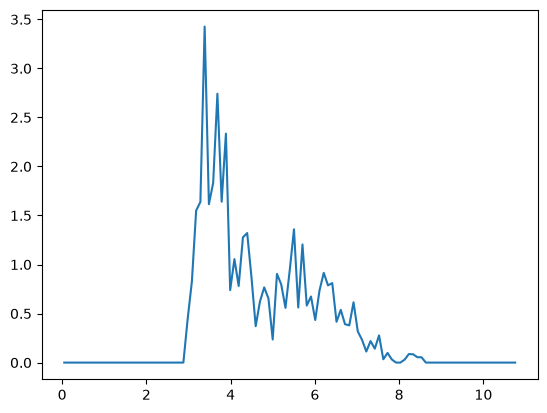

(992,)


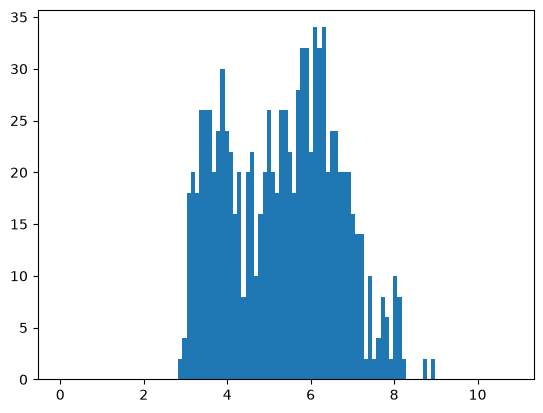

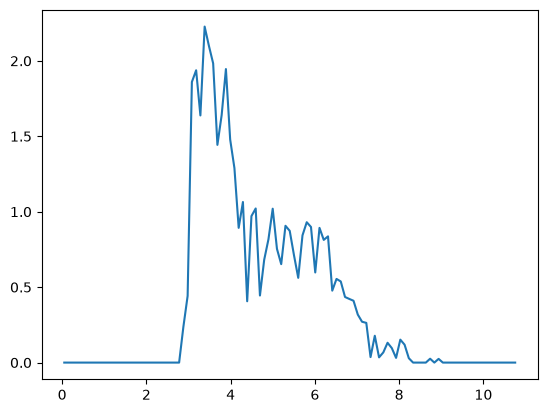

(992,)


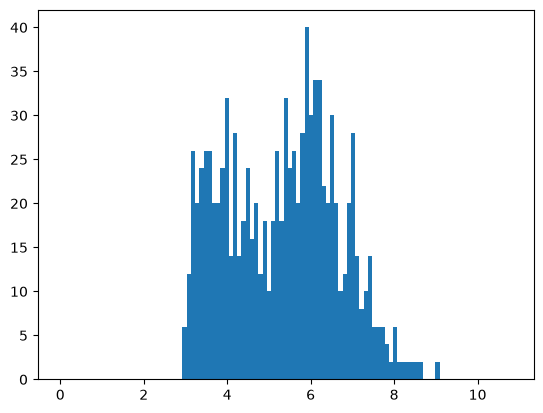

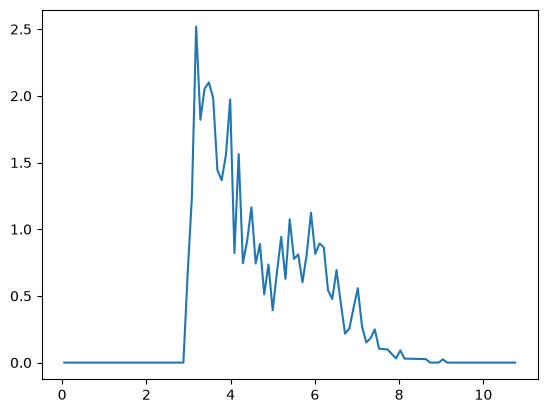

(992,)


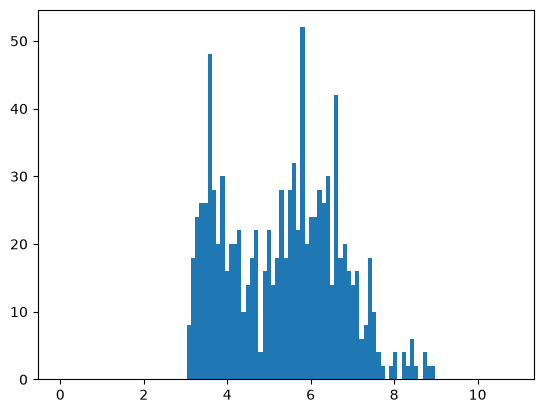

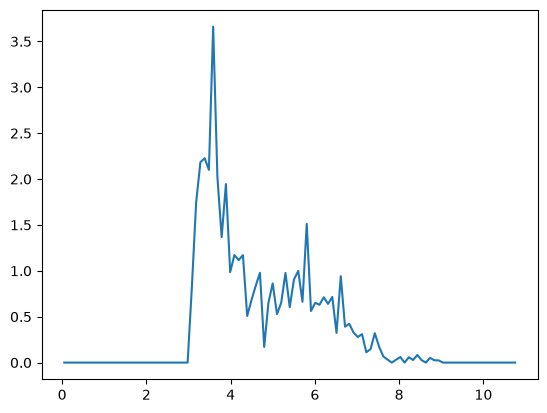

(992,)


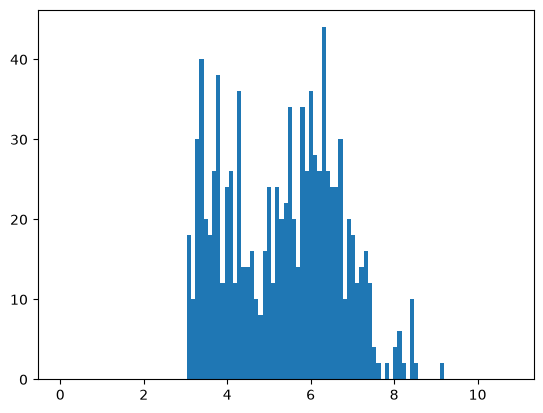

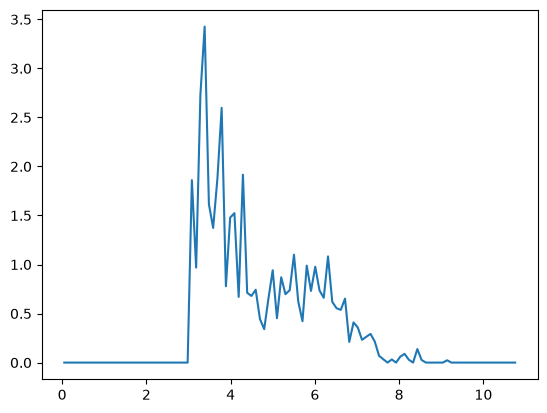

(992,)


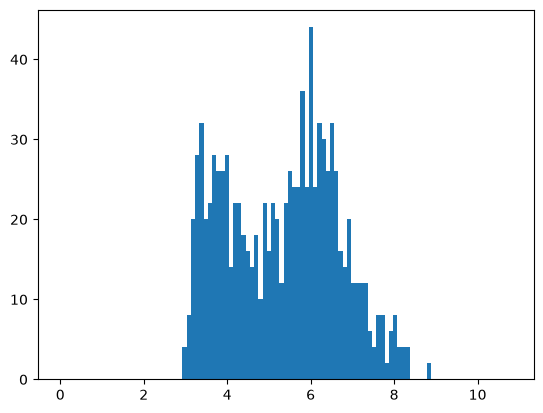

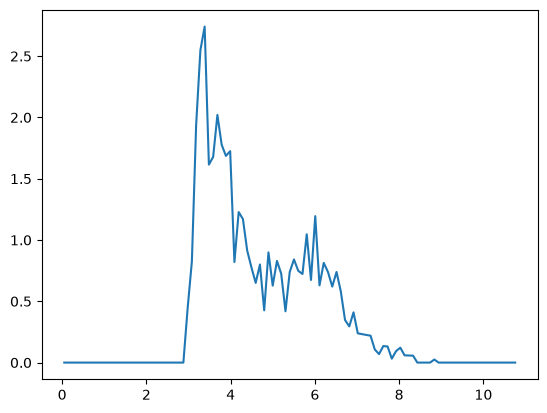

(992,)


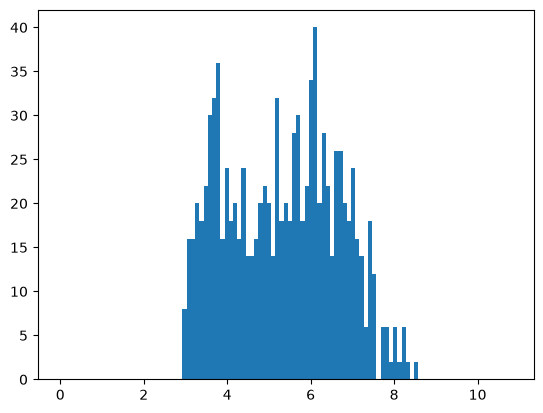

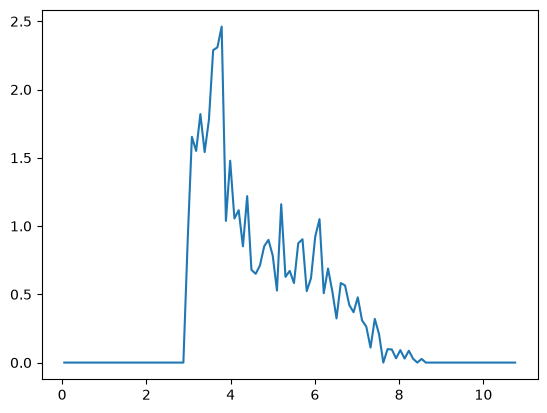

(992,)


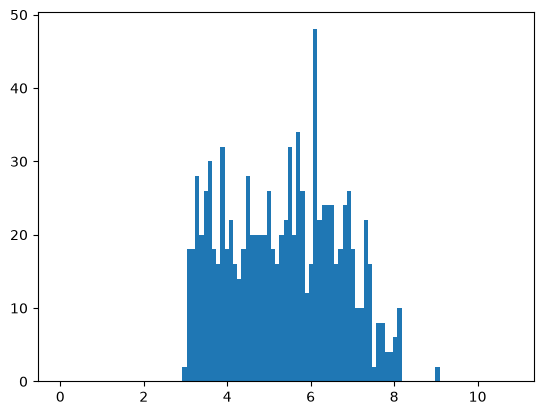

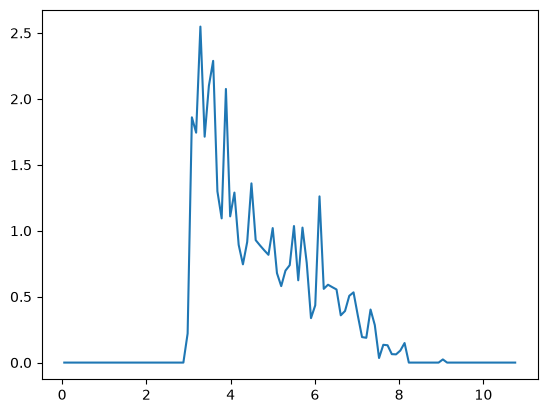

(992,)


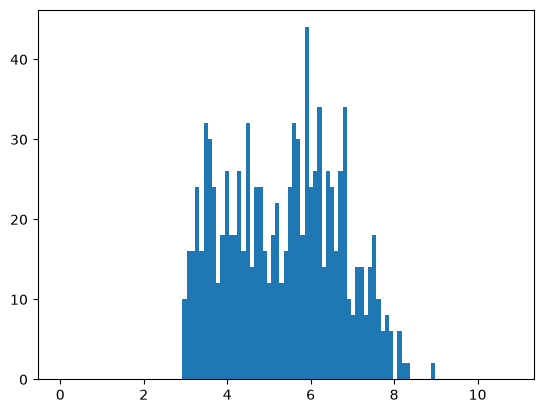

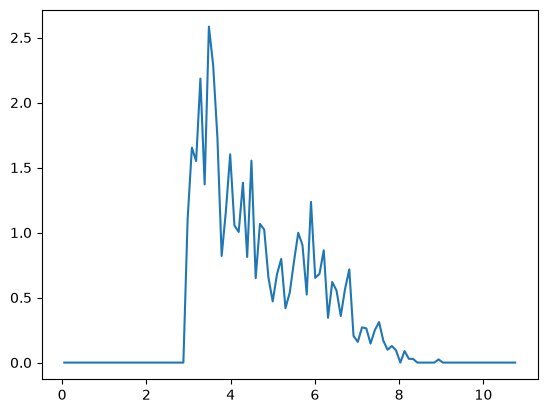

(992,)


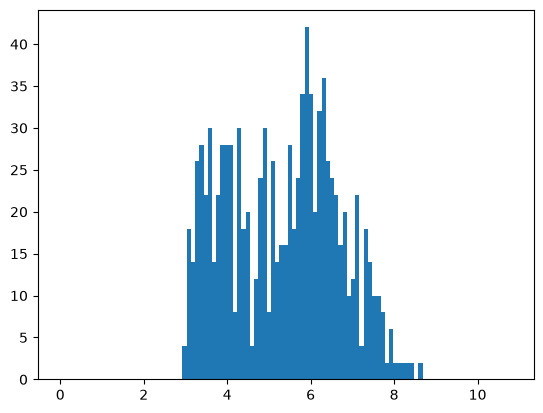

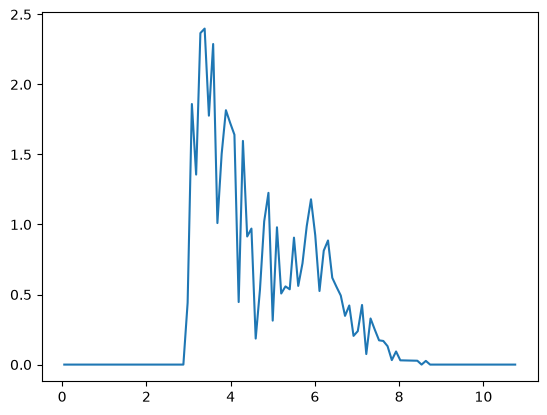

(992,)


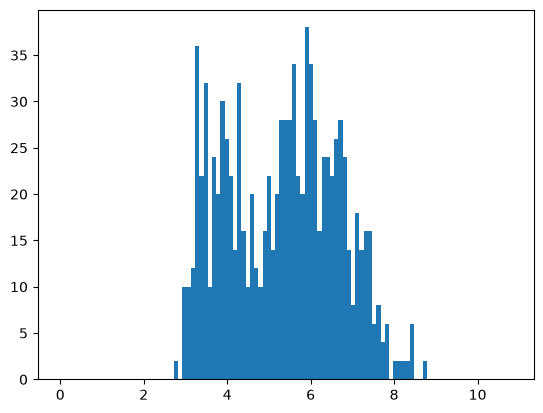

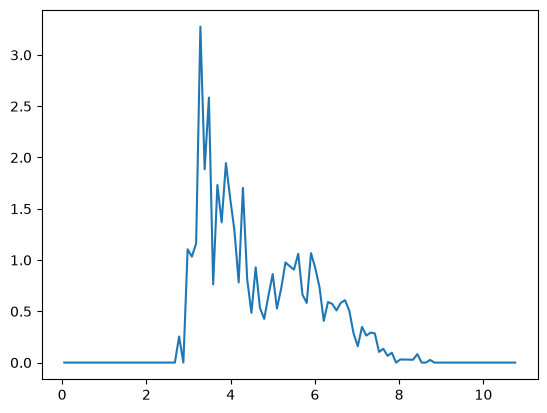

(992,)


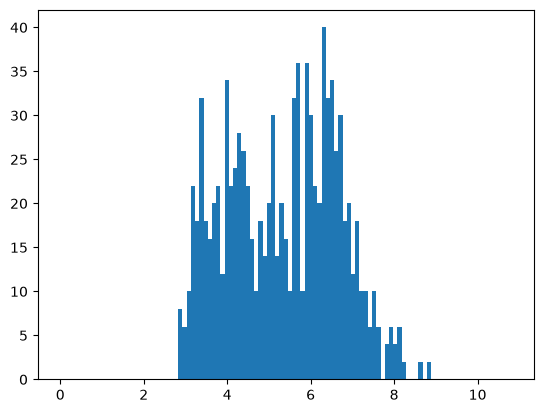

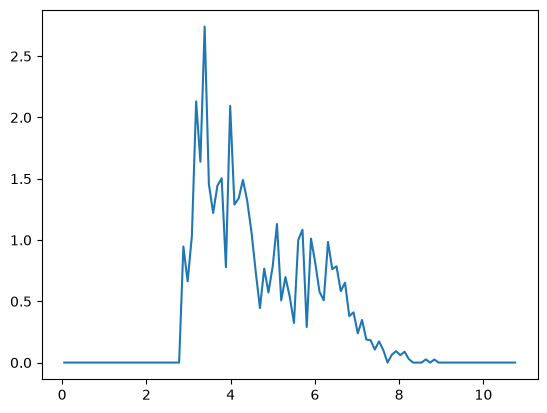

(992,)


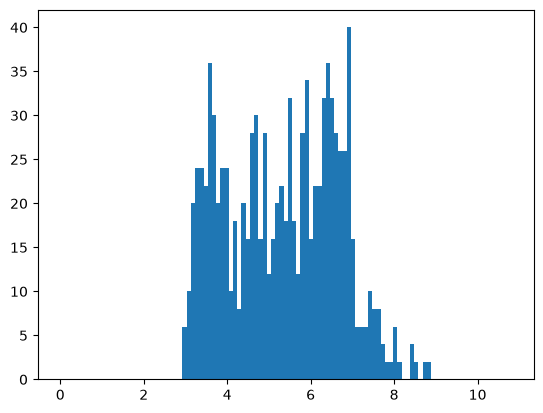

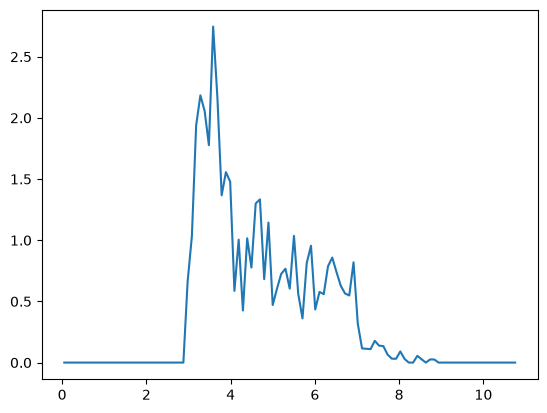

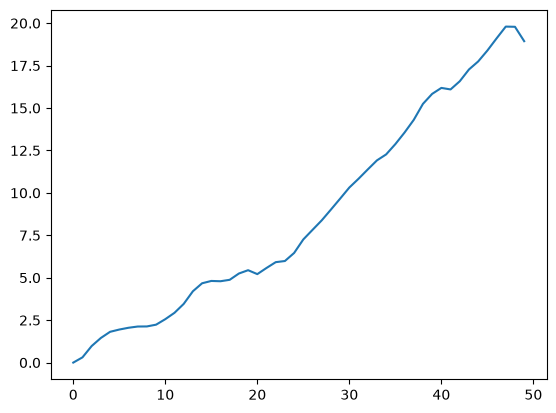

In [15]:
#odległości w angstremach
traj = np.load("zapis_trajektori.npy",mmap_mode="r")
traj = traj[:-1]
print(traj.shape)
dr = 0.1 #rozdzielczość bina histogramu
n_steps = int(L/dr)
co_ile_krok = 100

MSD_t = []

start_pos = traj[0]

for s in range(0,traj.shape[0],co_ile_krok):
    dists = []
    for i in range(traj.shape[1]):
        for j in range(traj.shape[1]):
            dist = pbc_delta(traj[s,i,:],traj[s,j,:],L)
            dist = np.linalg.norm(dist)
            dists.append(dist)

    dists = np.array(dists)   
    dists = dists[dists != 0]
    print(dists.shape)

    bins = np.linspace(0,L,n_steps)

    n_atoms, borders,_ = plt.hist(dists,bins)
    plt.show()

    N = traj.shape[1]
    r_bin = (borders[:-1] + borders[1:]) / 2
    rho = N / L**3

    g = n_atoms/(4*np.pi * r_bin**2 * dr * rho * N)
    plt.plot(r_bin,g)
    plt.show()

kroki = pbc_delta(traj[1:], traj[:-1], L)
przesuniecia = np.zeros_like(traj)
przesuniecia[1:] = np.cumsum(kroki, axis=0)
MSD_all = np.mean(np.sum(przesuniecia**2, axis=2), axis=1)

MSD_t = MSD_all[::co_ile_krok]

plt.plot(MSD_t)


        
    



